## Data Cleaning

### Import Kaggle Dataset

In [9]:
import pandas as pd
import os
import kagglehub

path = kagglehub.dataset_download("dillonmyrick/bells-palsy-clinical-trial")
files = os.listdir(path) # Lists files

csv_file = [f for f in files if f.endswith('.csv')][0] # Find the first file that ends in .csv
csv_path = os.path.join(path, csv_file) # Join path and CSV file

df = pd.read_csv(csv_path)
print(f"Successfully loaded: {csv_file}")

Successfully loaded: Bells Palsy Clinical Trial.csv


In [10]:
from sklearn.preprocessing import StandardScaler

#Changing Sex to dummy variables, Male = 1, Female = 0
df["Sex"]= (df["Sex"] == "Male").astype(int)

#Changing Within 24 hr to 0, >24 to ≤48 hr to 1, >48 to ≤72 hr to 2, REMOVED the Unknown
df["Time between onset of symptoms and start of treatment"] = df["Time between onset of symptoms and start of treatment"].map({"Within 24 hr": 0, ">24 to ≤48 hr": 1, ">48 to ≤72 hr": 2})


#Changing Received Prednisolone to No = 0, Yes = 1 and Received Acyclovir to No = 0, Yes = 1
df["Received Prednisolone"] = df["Received Prednisolone"].map({"Yes": 1, "No": 0})
df["Received Acyclovir"] = df["Received Acyclovir"].map({"Yes": 1, "No": 0})

#Changing Full Recovery in 3 months to No = 0, Yes = 1 and Full Recovery in 9 months to No = 0, Yes = 1
df["Full Recovery in 3 Months"] = df["Full Recovery in 3 Months"].map({"No": 0, "Yes": 1})
df["Full Recovery in 9 Months"] = df["Full Recovery in 9 Months"].map({"No": 0, "Yes": 1})

#Dropping Treatment Group since its the same as received prednislone/acyclovir
df= df.drop("Treatment Group", axis = 1)

#Convert to floats
df["Time between onset of symptoms and start of treatment"] = df["Time between onset of symptoms and start of treatment"].astype("Int64") # supports missing values
df["Received Prednisolone"] = df["Received Prednisolone"].astype(int)
df["Received Acyclovir"] = df["Received Acyclovir"].astype(int)
df["Full Recovery in 3 Months"] = df["Full Recovery in 3 Months"].astype(int)
df["Full Recovery in 9 Months"] = df["Full Recovery in 9 Months"].astype(int)

#Drop NA Rows
df = df.dropna()

# Features and Target Variables
x = df[["Sex", "Age", "Baseline Score on House–Brackmann scale", "Time between onset of symptoms and start of treatment", "Received Prednisolone", "Received Acyclovir"]]

y_3month_score = df["3-Month Score on House–Brackmann scale"]
y_3month_recovery = df["Full Recovery in 3 Months"]
y_9month_score = df["9-Month Score on House–Brackmann scale"]
y_9month_recovery = df["Full Recovery in 9 Months"]

#Standardize the Features
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

def clean_stats(x): # Helper function to clean output
    return round(float(x), 4)

## Feature Selection - Regression

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
import numpy as np
#Function to run all analyses and return results
def run_analysis(x, y, target_name, n_features = 3):
    feature_names = x.columns
    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
    
    scaler = StandardScaler()
    x_train = scaler.fit_transform(x_train)
    x_test = scaler.transform(x_test)
    model = LinearRegression()
    

    #All-in Selection
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)
    MSE_all = mean_squared_error(y_test, y_pred)
    R2_all = r2_score(y_test, y_pred)
    #results["All-in"] = [MSE_all, R2_all]

    #Forward Selection
    Forward = SFS(estimator = LinearRegression(), k_features = n_features, forward = True, floating = False, cv=3)
    Forward.fit(x_train, y_train)
    x_train_forward = Forward.transform(x_train)
    x_test_forward = Forward.transform(x_test)
    model_forward = LinearRegression()
    model_forward.fit(x_train_forward, y_train)
    y_pred_forward = model_forward.predict(x_test_forward)
    MSE_forward = mean_squared_error(y_test, y_pred_forward)
    R2_forward = r2_score(y_test, y_pred_forward)
    coef_names_forward = [feature_names[i] for i in Forward.k_feature_idx_]
    

    #Backward Selection
    Backward = SFS(estimator = LinearRegression(), k_features = n_features, forward = False, floating = False, cv=3)
    Backward.fit(x_train, y_train)
    x_train_backward = Backward.transform(x_train)
    x_test_backward = Backward.transform(x_test)
    model_backward = LinearRegression()
    model_backward.fit(x_train_backward, y_train)
    y_pred_backward = model_backward.predict(x_test_backward)
    MSE_backward = mean_squared_error(y_test, y_pred_backward)
    R2_backward = r2_score(y_test, y_pred_backward)
    coef_names_backward = [feature_names[i] for i in Backward.k_feature_idx_]

    #Bidirectional Selection
    Bidirectional = SFS(estimator = LinearRegression(), k_features = n_features, forward = True, floating = True, cv=3)
    Bidirectional.fit(x_train, y_train)
    x_train_bidirectional = Bidirectional.transform(x_train)
    x_test_bidirectional = Bidirectional.transform(x_test)
    model_bidirectional = LinearRegression()
    model_bidirectional.fit(x_train_bidirectional, y_train)
    y_pred_bidirectional = model_bidirectional.predict(x_test_bidirectional)
    MSE_bidirectional = mean_squared_error(y_test, y_pred_bidirectional)
    R2_bidirectional = r2_score(y_test, y_pred_bidirectional)
    coef_names_bidirectional = [feature_names[i] for i in Bidirectional.k_feature_idx_]

    #Score-based Selection (F-test)
    selector_f = SelectKBest(score_func=f_regression, k=n_features)
    selector_f.fit(x_train, y_train)
    x_train_f = selector_f.transform(x_train)
    x_test_f = selector_f.transform(x_test)
    model_f = LinearRegression()
    model_f.fit(x_train_f, y_train)
    y_pred_f = model_f.predict(x_test_f)
    MSE_f = mean_squared_error(y_test, y_pred_f)
    R2_f = r2_score(y_test, y_pred_f)
    coef_names_Ftest = np.array(feature_names)[selector_f.get_support()]
    
    #Muti-information score-based selection
    selector_mi = SelectKBest(score_func=mutual_info_regression, k=n_features)
    selector_mi.fit(x_train, y_train)
    x_train_mi = selector_mi.transform(x_train)
    x_test_mi = selector_mi.transform(x_test)
    model_mi = LinearRegression()
    model_mi.fit(x_train_mi, y_train)
    y_pred_mi = model_mi.predict(x_test_mi)
    MSE_mi = mean_squared_error(y_test, y_pred_mi)
    R2_mi = r2_score(y_test, y_pred_mi)
    coef_names_mi = np.array(feature_names)[selector_mi.get_support()]

    #Final Table of Results
    results = f"""
    {target_name}
    All-in:        MSE = {MSE_all:.03f}, R2 = {R2_all:.03f}, 
    Forward:       MSE = {MSE_forward:.03f}, R2 = {R2_forward:.03f}, Features = {coef_names_forward}
    Backward:      MSE = {MSE_backward:.03f}, R2 = {R2_backward:.03f}, Features = {coef_names_backward}
    Bidirectional: MSE = {MSE_bidirectional:.03f}, R2 = {R2_bidirectional:.03f}, Features = {coef_names_bidirectional}
    F-test:        MSE = {MSE_f:.03f}, R2 = {R2_f:.03f}, Features = {coef_names_Ftest}
    Mutual Info:   MSE = {MSE_mi:.03f}, R2 = {R2_mi:.03f}, Features = {coef_names_mi}
"""
    return results


In [12]:
results_y1 = run_analysis(x, y_3month_score, "3-month score")
results_y2 = run_analysis(x, y_3month_recovery, "Full Recovery in 3 Months")
results_y3 = run_analysis(x, y_9month_score, "9-month score")
results_y4 = run_analysis(x, y_9month_recovery, "Full Recovery in 9 Months")
print("3-month score results:", results_y1)
print("Full Recovery in 3 Months results:", results_y2)
print("9-month score results:", results_y3)
print("Full Recovery in 9 Months results:", results_y4)

3-month score results: 
    3-month score
    All-in:        MSE = 0.265, R2 = 0.145, 
    Forward:       MSE = 0.270, R2 = 0.128, Features = ['Age', 'Baseline Score on House–Brackmann scale', 'Received Prednisolone']
    Backward:      MSE = 0.270, R2 = 0.128, Features = ['Age', 'Baseline Score on House–Brackmann scale', 'Received Prednisolone']
    Bidirectional: MSE = 0.270, R2 = 0.128, Features = ['Age', 'Baseline Score on House–Brackmann scale', 'Received Prednisolone']
    F-test:        MSE = 0.270, R2 = 0.128, Features = ['Age' 'Baseline Score on House–Brackmann scale' 'Received Prednisolone']
    Mutual Info:   MSE = 0.284, R2 = 0.083, Features = ['Sex' 'Age' 'Baseline Score on House–Brackmann scale']

Full Recovery in 3 Months results: 
    Full Recovery in 3 Months
    All-in:        MSE = 0.149, R2 = 0.075, 
    Forward:       MSE = 0.151, R2 = 0.066, Features = ['Age', 'Baseline Score on House–Brackmann scale', 'Received Prednisolone']
    Backward:      MSE = 0.151, R2 = 

## Model Selection - Linear Regression, Decision Tree, Random Forest, SVR

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR


#Function to run all Regression Techniques and return results
def run_regression_analysis(x, y, target_name, n_features=6):
    features = x.columns
    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=3)

    scaler = StandardScaler()
    x_train = scaler.fit_transform(x_train)
    x_test = scaler.transform(x_test)

    results = {}

    def evaluate_model(model, model_name):
        sfs = SFS(estimator=model, k_features=n_features, forward=True, floating=True, cv=3)
        sfs.fit(x_train, y_train)
        x_train_sfs = sfs.transform(x_train)
        x_test_sfs = sfs.transform(x_test)
        model.fit(x_train_sfs, y_train)
        y_pred = model.predict(x_test_sfs)
        mse = mean_squared_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)
        selected_features = [features[i] for i in sfs.k_feature_idx_]
        return mse, r2, selected_features

    #Models being evaluated
    results["Linear Regression"] = evaluate_model(LinearRegression(), "Linear Regression")
    results["Decision Tree Regressor"] = evaluate_model(DecisionTreeRegressor(max_depth = 5), "Decision Tree Regressor")
    results["Random Forest Regressor"] = evaluate_model(RandomForestRegressor(n_estimators=100, max_depth=5), "Random Forest Regressor")
    results["Support Vector Regressor"] = evaluate_model(SVR(kernel='rbf'), "Support Vector Regressor")

    #Format Results
    Formatted_results = {
        model_name: {
            "MSE": values[0],
            "R2": values[1],
            "Selected Features": values[2]
        }
        for model_name, values in results.items()
    }
    print(f"\n==================== {target_name} ====================")

    for model, vals in Formatted_results.items():
        print(f"""
    {model}
    MSE: {vals['MSE']:.3f}
    R2: {vals['R2']:.3f}
    Features: {vals['Selected Features']}
    """)

    return Formatted_results


In [14]:
results_3monthscore = run_regression_analysis(x, y_3month_score, "3-month score")
results_3month_recovery = run_regression_analysis(x, y_3month_recovery, "Full Recovery in 3 Months")
results_9month_score = run_regression_analysis(x, y_9month_score, "9-month score")
results_9month_recovery = run_regression_analysis(x, y_9month_recovery, "Full Recovery in 9 Months")



==================== 3-month score ====================

    Linear Regression
    MSE: 0.409
    R2: 0.201
    Features: ['Sex', 'Age', 'Baseline Score on House–Brackmann scale', 'Time between onset of symptoms and start of treatment', 'Received Prednisolone', 'Received Acyclovir']
    

    Decision Tree Regressor
    MSE: 0.496
    R2: 0.030
    Features: ['Sex', 'Age', 'Baseline Score on House–Brackmann scale', 'Time between onset of symptoms and start of treatment', 'Received Prednisolone', 'Received Acyclovir']
    

    Random Forest Regressor
    MSE: 0.419
    R2: 0.181
    Features: ['Sex', 'Age', 'Baseline Score on House–Brackmann scale', 'Time between onset of symptoms and start of treatment', 'Received Prednisolone', 'Received Acyclovir']
    

    Support Vector Regressor
    MSE: 0.516
    R2: -0.007
    Features: ['Sex', 'Age', 'Baseline Score on House–Brackmann scale', 'Time between onset of symptoms and start of treatment', 'Received Prednisolone', 'Received Acyclovi

## Plotting

In [22]:
import matplotlib.pyplot as plt

def plot_predvsactual(model, x, y):

    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=3)
    scaler = StandardScaler()
    x_train = scaler.fit_transform(x_train)
    x_test = scaler.transform(x_test)

    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)

    plt.figure()
    plt.scatter(y_test, y_pred)
    
    # Perfect prediction line
    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val], 'r--')

    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")
    plt.title(f"Predicted vs Actual for {y.name}")
    plt.show()




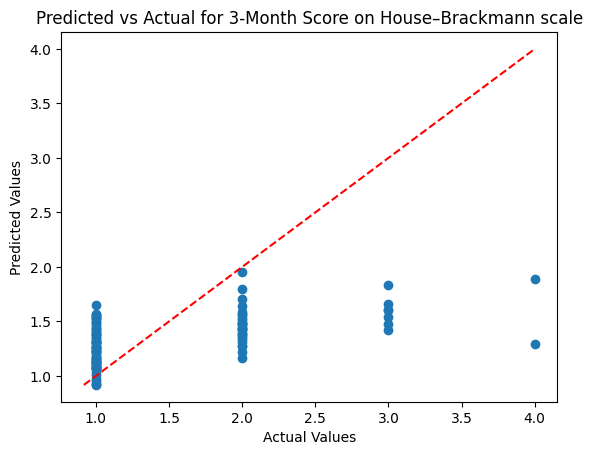

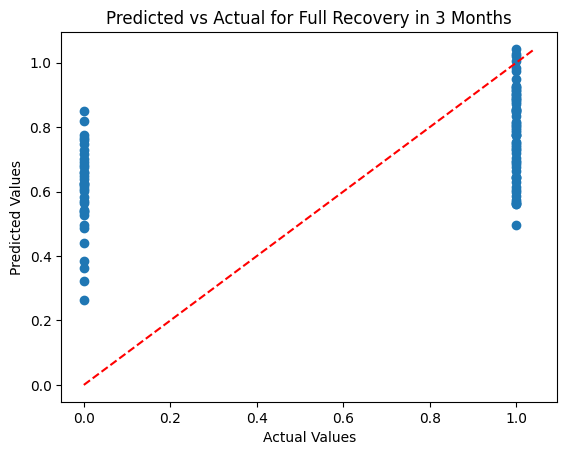

In [24]:
plot_predvsactual(LinearRegression(), x, y_3month_score)
#plot_predvsactual(DecisionTreeRegressor(max_depth = 5), x, y_3month_score)
#plot_predvsactual(RandomForestRegressor(n_estimators=100, max_depth=5), x, y_3month_score)
#plot_predvsactual(SVR(kernel='rbf'), x, y_3month_score)
plot_predvsactual(LinearRegression(), x, y_3month_recovery)


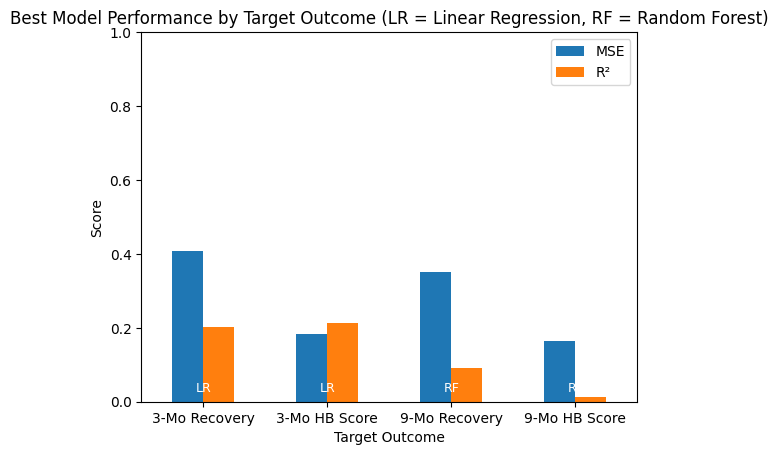

In [17]:
data = {
    'Category': ['3-Mo Recovery', '3-Mo HB Score', '9-Mo Recovery', '9-Mo HB Score'],
    'MSE': [.409, .182, .350, .165],
    'R²': [.201, .213, .090, .013]
}

df = pd.DataFrame(data)
df.set_index('Category').plot(kind='bar')

for i, label in enumerate(['LR', 'LR', 'RF', 'RF']):
    plt.text(i, 0.02, label, ha='center', va='bottom', fontsize=9, color = 'white')
plt.title('Best Model Performance by Target Outcome (LR = Linear Regression, RF = Random Forest)')
plt.xticks(rotation=0)
plt.xlabel('Target Outcome')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.show()

